# Template PSF quality: typical PSF per tract, and variation across tracts/patches

Evaluates the `template_coadd` ("goodSeeing") templates built by
[`QuickTemplate.yaml`](../configs/QuickTemplate.yaml) for a DESGW target field, before
they are used as difference-imaging templates in
[`desgw_ap_pipe.yaml`](../configs/desgw_ap_pipe.yaml). For every (tract, patch, band):

* measures the **template's own PSF model** (its `CoaddPsf`) at several points across
  the patch's real (non-`NO_DATA`) footprint, giving a typical FWHM and a measure of
  how much the PSF varies *within* a single patch;
* cross-matches the coadd's contributing (visit, detector) pairs against their native
  `preliminary_visit_summary` PSF measurements, i.e. the seeing each input image
  actually had *before* coaddition, weighted the same way `assembleTemplateCoadd`
  weighted them -- a cheap sanity check that the coadd PSF model is behaving as
  expected and a way to see which patches were built from only one or two visits.

Aggregating per-patch results by tract gives the "typical PSF per tract" picture, and
plotting them spatially (and patch-by-patch within a tract) shows where templates are
built from poorer or more heterogeneous seeing than their neighbors -- exactly the
patches worth a second look before trusting their difference images.

Owner: **Sean MacBride** [@seanmacb](https://github.com/seanmacb/)

Last Verified to Run: **2026-10-01**, against `DECam/templates/S250830bp` on
`lsst-scipipe-13.1.0`.

**Kernel:** this notebook needs the LSST Science Pipelines kernel (`lsst_stack` /
"LSST Science Pipelines"), i.e. a Jupyter kernel launched from an environment where
`source /shares/soares-santos.physik.uzh/envs/lsst_stack/loadLSST.sh && setup
lsst_distrib -c && setup -j -r $OBSDECAM` has already run.

**A note on dataset-type names:** this notebook was written against the "coaddition
v2" naming used by `lsst-scipipe-13.1.0` (`template_coadd`, `preliminary_visit_summary`).
An older stack/collection built with the legacy `goodSeeingCoadd` task may use
different dataset type names (e.g. `goodSeeingCoadd`, `visitSummary`) and a different
`CoaddInputs.ccds` schema -- check with `butler query-dataset-types` before pointing
this at such a collection.


## Parameters

In [25]:
REPO = "/shares/soares-santos.physik.uzh/ButlerProjects/desgw_postgres"

# Collection holding the template_coadd ("goodSeeing") coadds built by
# QuickTemplate.yaml for one DESGW target field, e.g. "DECam/templates/<event_name>".
TEMPLATE_COLLECTION = ["DECam/templates/bestSeeing_wide_gri","skymaps"]

SKYMAP_NAME = "decam_rings_v1"

COADD_DATASET_TYPE = "template_coadd"
VISIT_SUMMARY_DATASET_TYPE = "preliminary_visit_summary"

# Restrict to specific tracts/bands, e.g. TRACTS = [195, 196]. None processes every
# (tract, patch, band) template_coadd found in TEMPLATE_COLLECTION.
TRACTS = None
BANDS = "g"

# Restrict to one part of the sky, so the templates of a single GW event can be
# analyzed at a time. A patch is kept if its centre lies inside the box (so patches
# straddling the edge are kept or dropped by their centre). RA_MIN > RA_MAX means the
# box wraps through RA = 0. Applies both to patches measured here and to rows loaded
# from PRECOMPUTED_CSV. Leave both None for the whole collection.
#
# SKY_EVENT: read RA_MIN/RA_MAX/DEC_MIN/DEC_MAX from
#            <EVENTS_DIR>/<SKY_EVENT>/too_run.conf, e.g. "S250830bp".
# SKY_BOX:   explicit (ra_min, ra_max, dec_min, dec_max) in degrees; wins over SKY_EVENT.
SKY_EVENT = None
EVENTS_DIR = "../too_run/events"
SKY_BOX = (315,330,-80,-75)
SEVENT="S250830bp"

# Cap the number of template coadds processed -- useful for a quick smoke test (e.g.
# 40) before committing to a full run on every patch. None processes everything.
MAX_PATCHES = None

# Points sampled within each patch's real (non-NO_DATA) footprint, used both for the
# typical PSF of that patch and for how much the PSF varies within it.
N_SAMPLE_POINTS = 9
RANDOM_SEED = 0

# QA thresholds used later to flag patches worth a second look. Tune to taste.
MIN_COVERAGE_FRAC = 0.05       # less than this fraction of real pixels -> unreliable
MIN_INPUTS_FOR_CHECK = 2       # fewer contributing (visit, detector) pairs -> can't cross-check
OUTLIER_MAD_SIGMA = 3.0        # |fwhm - tract/band median| this many MADs away -> outlier
TEMPLATE_VS_INPUT_MAX_DIFF = 0.15  # arcsec; template vs. weighted-input FWHM mismatch

OUTPUT_DIR = f"./bestSeeing_wide_gri/{BANDS}/{SEVENT}"  # where the per-patch table and tract summary CSVs are written

# Path to a template_psf_per_patch.csv written by measure_template_psf.py (the
# parallel version of the measurement loop below, e.g. run via
# run-measure-template-psf.sh on a compute node). If set, the notebook loads it
# instead of re-measuring every patch serially. None measures in the notebook.
PRECOMPUTED_CSV = f"/shares/soares-santos.physik.uzh/ButlerProjects/desgw_postgres/logs/templatePsf/bestSeeing_wide_gri/{BANDS}/template_psf_per_patch.csv"

## Connect to the butler

Reading the full pixel data of every `template_coadd` in a collection this size takes
~90 s *per patch* over this filesystem -- far too slow for ~1000+ patches. Everything
below instead fetches individual Exposure **components** (`mask`, `psf`, `wcs`,
`coaddInputs`) rather than the whole `ExposureF`, which is a couple of orders of
magnitude faster since it skips the image and variance planes entirely.


In [26]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import lsst.geom as geom
from lsst.daf.butler import Butler

GAUSSIAN_SIGMA_TO_FWHM = 2.3548200450309493  # 2 * sqrt(2 * ln(2))

butler = Butler(REPO, collections=TEMPLATE_COLLECTION)
skymap = butler.get("skyMap", skymap=SKYMAP_NAME)

print(f"Repo: {REPO}")
print(f"Template collection: {TEMPLATE_COLLECTION}")
print(f"Skymap: {SKYMAP_NAME}")


Repo: /shares/soares-santos.physik.uzh/ButlerProjects/desgw_postgres
Template collection: ['DECam/templates/bestSeeing_wide_gri', 'skymaps']
Skymap: decam_rings_v1


## Discover the available template patches

Set `SKY_EVENT` or `SKY_BOX` in the parameters cell to keep only the patches inside one GW event's sky area.

In [27]:
import functools
import re
from pathlib import Path


def resolve_sky_box():
    """(ra_min, ra_max, dec_min, dec_max) in degrees, or None for the whole sky."""
    if SKY_BOX is not None:
        return tuple(float(v) for v in SKY_BOX)
    if SKY_EVENT is None:
        return None
    conf = Path(EVENTS_DIR) / SKY_EVENT / "too_run.conf"
    values = {}
    for line in conf.read_text().splitlines():
        m = re.match(r"\s*(RA_MIN|RA_MAX|DEC_MIN|DEC_MAX)=([-+0-9.eE]+)", line)
        if m:
            values[m.group(1)] = float(m.group(2))
    missing = {"RA_MIN", "RA_MAX", "DEC_MIN", "DEC_MAX"} - values.keys()
    if missing:
        raise ValueError(f"{conf} does not define {sorted(missing)}")
    return values["RA_MIN"], values["RA_MAX"], values["DEC_MIN"], values["DEC_MAX"]


@functools.lru_cache(maxsize=None)
def patch_center_sky(tract, patch):
    """On-sky (ra, dec) in degrees of a patch's centre, from the skymap geometry."""
    tract_info = skymap[tract]
    patch_info = tract_info[patch]
    wcs = tract_info.getWcs()
    center_pix = geom.Box2D(patch_info.getInnerBBox()).getCenter()
    center_sky = wcs.pixelToSky(center_pix)
    return center_sky.getRa().asDegrees(), center_sky.getDec().asDegrees()


def in_sky_box(ra, dec, box):
    ra_min, ra_max, dec_min, dec_max = box
    in_ra = (ra - ra_min) % 360.0 <= (ra_max - ra_min) % 360.0
    return in_ra and dec_min <= dec <= dec_max


sky_box = resolve_sky_box()
if sky_box is None:
    print("Sky region: whole collection")
else:
    print("Sky region: RA {:g} to {:g} deg, Dec {:g} to {:g} deg".format(*sky_box))

refs = list(butler.registry.queryDatasets(COADD_DATASET_TYPE, collections=TEMPLATE_COLLECTION))
n_in_collection = len(refs)

if sky_box is not None:
    refs = [r for r in refs
            if in_sky_box(*patch_center_sky(r.dataId["tract"], r.dataId["patch"]), sky_box)]
    print(f"{len(refs)} / {n_in_collection} {COADD_DATASET_TYPE} datasets inside the sky region")
    if not refs:
        raise RuntimeError("No template patches fall inside the requested sky region")

if TRACTS is not None:
    refs = [r for r in refs if r.dataId["tract"] in TRACTS]
if BANDS is not None:
    refs = [r for r in refs if r.dataId["band"] in BANDS]
if MAX_PATCHES is not None:
    refs = refs[:MAX_PATCHES]

tracts_found = sorted({r.dataId["tract"] for r in refs})
bands_found = sorted({r.dataId["band"] for r in refs})

print(f"{len(refs)} {COADD_DATASET_TYPE} datasets selected")
print(f"Tracts ({len(tracts_found)}): {tracts_found}")
print(f"Bands: {bands_found}")

Sky region: RA 315 to 330 deg, Dec -80 to -75 deg
779 / 60573 template_coadd datasets inside the sky region
250 template_coadd datasets selected
Tracts (15): [195, 196, 197, 247, 248, 249, 250, 306, 307, 308, 309, 372, 373, 374, 375]
Bands: ['g']


## Per-patch PSF measurement

Two independent measurements per `(tract, patch, band)`:

1. **`measure_template_psf`** -- samples `N_SAMPLE_POINTS` pixels drawn from the
   coadd's actual (non-`NO_DATA`) footprint (not a blind grid, which would mostly land
   on empty pixels for a partially-covered patch) and evaluates the coadd's own
   `CoaddPsf` at each, converting the trace-radius "sigma" to a FWHM in arcsec via the
   coadd's local pixel scale. The median across points is the patch's typical PSF; the
   spread across points is how much the PSF model itself varies within one patch.
2. **`measure_input_psf`** -- reads the `coaddInputs.ccds` table (the (visit, detector,
   weight) triples `assembleTemplateCoadd` actually combined) and looks each one up in
   its own `preliminary_visit_summary` record (cached across patches, since the same
   ~90 visits feed many patches) to get the native, pre-coaddition PSF FWHM of every
   input. The coadd-weighted median of those is compared against (1) as a sanity check
   that the template's PSF model is behaving as expected, and it also records how many
   inputs a patch actually had -- a patch built from a single visit has no redundancy
   to catch a bad input.


In [28]:
def _sample_good_points(mask, n_samples, rng):
    """Up to n_samples (x, y) pixel coords drawn from the coadd's real footprint."""
    no_data = mask.getPlaneBitMask("NO_DATA")
    good = (mask.array & no_data) == 0
    ys, xs = np.where(good)
    if len(xs) == 0:
        return np.array([]), np.array([]), 0.0
    coverage = len(xs) / good.size
    n = min(n_samples, len(xs))
    idx = rng.choice(len(xs), size=n, replace=False)
    bbox = mask.getBBox()
    return xs[idx] + bbox.getMinX(), ys[idx] + bbox.getMinY(), coverage


def measure_template_psf(butler, ref, n_samples, rng):
    mask = butler.get(ref.makeComponentRef("mask"))
    xs, ys, coverage = _sample_good_points(mask, n_samples, rng)
    empty = dict(template_psf_fwhm_median=np.nan, template_psf_fwhm_std=np.nan,
                 n_psf_samples=0, coverage_frac=coverage)
    if len(xs) == 0:
        return empty

    psf = butler.get(ref.makeComponentRef("psf"))
    wcs = butler.get(ref.makeComponentRef("wcs"))

    fwhms = []
    for x, y in zip(xs, ys):
        point = geom.Point2D(float(x), float(y))
        try:
            shape = psf.computeShape(point)
        except Exception:
            continue  # CoaddPsf has no input coverage at this exact point
        pixel_scale = wcs.getPixelScale(point).asArcseconds()
        fwhms.append(shape.getTraceRadius() * GAUSSIAN_SIGMA_TO_FWHM * pixel_scale)

    if not fwhms:
        return empty
    return dict(
        template_psf_fwhm_median=float(np.median(fwhms)),
        template_psf_fwhm_std=float(np.std(fwhms)),
        n_psf_samples=len(fwhms),
        coverage_frac=coverage,
    )


_visit_summary_cache = {}


def _get_visit_summary(butler, visit):
    if visit not in _visit_summary_cache:
        vrefs = list(butler.registry.queryDatasets(
            VISIT_SUMMARY_DATASET_TYPE, collections=[TEMPLATE_COLLECTION], visit=visit,
        ))
        _visit_summary_cache[visit] = butler.get(vrefs[0]) if vrefs else None
    return _visit_summary_cache[visit]


def measure_input_psf(butler, ref):
    empty = dict(n_inputs=0, input_psf_fwhm_weighted_median=np.nan,
                 input_psf_fwhm_min=np.nan, input_psf_fwhm_max=np.nan)
    try:
        coadd_inputs = butler.get(ref.makeComponentRef("coaddInputs"))
    except Exception:
        return empty

    ccds = coadd_inputs.ccds.asAstropy()
    fwhms, weights = [], []
    for row in ccds:
        summary = _get_visit_summary(butler, int(row["visit"]))
        if summary is None:
            continue
        ids = np.asarray(summary["id"])  # one row per detector; id == detector number
        match = ids == int(row["ccd"])
        if not match.any():
            continue
        sigma = np.asarray(summary["psfSigma"])[match][0]
        pixel_scale = np.asarray(summary["pixelScale"])[match][0]
        fwhms.append(sigma * GAUSSIAN_SIGMA_TO_FWHM * pixel_scale)
        weights.append(float(row["weight"]))

    result = dict(empty)
    result["n_inputs"] = len(ccds)
    if not fwhms:
        return result

    fwhms = np.asarray(fwhms)
    weights = np.asarray(weights)
    order = np.argsort(fwhms)
    cum_weight = np.cumsum(weights[order])
    median_fwhm = fwhms[order][np.searchsorted(cum_weight, cum_weight[-1] / 2.0)]

    result.update(
        input_psf_fwhm_weighted_median=float(median_fwhm),
        input_psf_fwhm_min=float(fwhms.min()),
        input_psf_fwhm_max=float(fwhms.max()),
    )
    return result


## Run over all selected patches

Each patch needs a handful of small component reads plus (amortized) one
`preliminary_visit_summary` fetch per *new* visit, so this is dominated by filesystem
round-trips rather than data volume. An ETA is printed after the first 10 patches.

This loop is serial, which is fine for a tract or two. For larger sky areas run
[`measure_template_psf.py`](measure_template_psf.py) instead (via
[`run-measure-template-psf.sh`](run-measure-template-psf.sh) on a compute node),
which does the same measurement across many worker processes, then set
`PRECOMPUTED_CSV` in the parameters cell to the `template_psf_per_patch.csv` it writes.


In [29]:
if PRECOMPUTED_CSV is not None:
    df = pd.read_csv(PRECOMPUTED_CSV)
    print(f"Loaded {len(df)} patches from {PRECOMPUTED_CSV}")
    if sky_box is not None:
        inside = [in_sky_box(*patch_center_sky(t, p), sky_box)
                  for t, p in zip(df["tract"], df["patch"])]
        df = df[inside].reset_index(drop=True)
        print(f"Kept {len(df)} patches inside the sky region")
        if df.empty:
            raise RuntimeError("No rows of PRECOMPUTED_CSV fall inside the requested sky region")
    tracts_found = sorted(df["tract"].unique())
else:
    rng = np.random.default_rng(RANDOM_SEED)
    records = []
    t_start = time.time()

    for i, ref in enumerate(refs):
        row = dict(ref.dataId.mapping)
        row.update(measure_template_psf(butler, ref, N_SAMPLE_POINTS, rng))
        row.update(measure_input_psf(butler, ref))
        records.append(row)

        if i == 9:
            elapsed = time.time() - t_start
            eta_min = elapsed / 10 * len(refs) / 60
            print(f"...10/{len(refs)} patches in {elapsed:.1f} s "
                  f"(estimated total: {eta_min:.1f} min)")
        elif (i + 1) % 100 == 0:
            print(f"...{i + 1}/{len(refs)} patches "
                  f"({(time.time() - t_start) / 60:.1f} min elapsed)")

    print(f"Done: {len(records)} patches in {(time.time() - t_start) / 60:.1f} min")

    df = pd.DataFrame.from_records(records)
    df["template_vs_input_diff"] = (
        df["template_psf_fwhm_median"] - df["input_psf_fwhm_weighted_median"]
    )
    df.to_csv(f"{OUTPUT_DIR}/template_psf_per_patch.csv", index=False)

df.head()

Loaded 15670 patches from /shares/soares-santos.physik.uzh/ButlerProjects/desgw_postgres/logs/templatePsf/bestSeeing_wide_gri/g/template_psf_per_patch.csv
Kept 250 patches inside the sky region


,band,skymap,tract,patch,template_psf_fwhm_median,template_psf_fwhm_std,n_psf_samples,coverage_frac,n_inputs,input_psf_fwhm_weighted_median,input_psf_fwhm_min,input_psf_fwhm_max,error,template_vs_input_diff
0,g,decam_rings_v1,195,30,1.596538,0.010150,9,0.010133,1,1.507419,1.507419,1.507419,NaN,0.089119
1,g,decam_rings_v1,195,31,1.557894,0.017683,9,0.071047,1,1.507419,1.507419,1.507419,NaN,0.050475
2,g,decam_rings_v1,196,12,1.362089,0.019988,9,0.524317,4,1.343506,1.342833,1.411541,NaN,0.018583
3,g,decam_rings_v1,196,13,1.360258,0.016835,9,0.446909,5,1.379724,1.342833,1.444422,NaN,-0.019467
4,g,decam_rings_v1,196,14,1.445200,0.022713,9,0.832334,4,1.385781,1.379724,1.445986,NaN,0.059419


## Typical PSF per tract

Median/spread of the per-patch template PSF, grouped by tract and band -- the
"typical PSF per tract" the question started with.


In [30]:
tract_summary = (
    df.groupby(["tract", "band"])["template_psf_fwhm_median"]
    .agg(fwhm_median="median", fwhm_mean="mean", fwhm_std="std",
         fwhm_min="min", fwhm_max="max", n_patches="count")
    .reset_index()
    .sort_values(["band", "tract"])
)
# tract_summary.to_csv(f"{OUTPUT_DIR}/template_psf_per_tract.csv", index=False)
tract_summary


,tract,band,fwhm_median,fwhm_mean,fwhm_std,fwhm_min,fwhm_max,n_patches
0,195,g,1.577216,1.577216,0.027326,1.557894,1.596538,2
1,196,g,1.376095,1.390511,0.051224,1.318949,1.457790,21
2,197,g,1.369320,1.379276,0.050360,1.320370,1.486923,12
3,247,g,1.400389,1.420409,0.064727,1.367884,1.538388,6
4,248,g,1.427600,1.421673,0.047378,1.356948,1.561828,35
5,249,g,1.362562,1.356264,0.050535,1.199897,1.438203,36
6,250,g,1.287579,1.302280,0.048835,1.261981,1.399168,6
7,306,g,1.463821,1.468878,0.106018,1.371643,1.576230,4
8,307,g,1.460526,1.462285,0.050378,1.286084,1.542853,30
9,308,g,1.335271,1.348707,0.081015,1.205413,1.463518,36


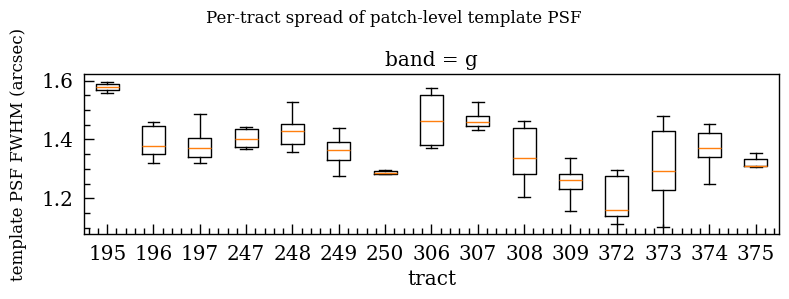

In [31]:
bands_present = sorted(df["band"].dropna().unique())
fig, axes = plt.subplots(len(bands_present), 1,
                          figsize=(max(8, 0.4 * len(tracts_found)), 3 * len(bands_present)),
                          squeeze=False)

for ax, band in zip(axes[:, 0], bands_present):
    sub = df[df["band"] == band]
    tracts_sorted = sorted(sub["tract"].unique())
    data = [sub.loc[sub["tract"] == t, "template_psf_fwhm_median"].dropna() for t in tracts_sorted]
    ax.boxplot(data, tick_labels=[str(t) for t in tracts_sorted], showfliers=False)
    ax.set_title(f"band = {band}")

axes[-1, 0].set_xlabel("tract")
fig.supylabel("template PSF FWHM (arcsec)")
fig.suptitle("Per-tract spread of patch-level template PSF")
fig.tight_layout()
# fig.savefig(os.path.join(OUTPUT_DIR,"PSF_across_Templates.pdf"),dpi=300)

## Spatial variation across tracts and patches

Each patch's on-sky center (from the skymap geometry, independent of the measurement
above) colored by its template PSF FWHM -- the spatial picture of where templates are
built from better or worse seeing. RA is scaled by cos(Dec) around the field's mean
position so the plot isn't visually distorted at this field's high |Dec|; this is a
quick-look projection, not an equal-area one.


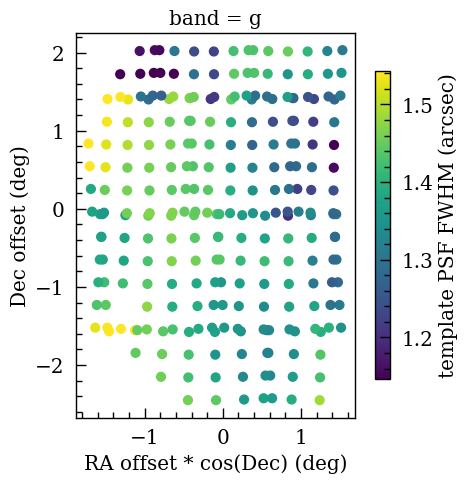

In [32]:
centers = {}
for tract, patch in df[["tract", "patch"]].drop_duplicates().itertuples(index=False):
    centers[(tract, patch)] = patch_center_sky(tract, patch)

df["ra"] = [centers[(t, p)][0] for t, p in zip(df["tract"], df["patch"])]
df["dec"] = [centers[(t, p)][1] for t, p in zip(df["tract"], df["patch"])]

ra0, dec0 = df["ra"].mean(), df["dec"].mean()
df["x_deg"] = (df["ra"] - ra0) * np.cos(np.radians(dec0))
df["y_deg"] = df["dec"] - dec0

fig, axes = plt.subplots(1, len(bands_present), figsize=(5 * len(bands_present), 5),
                          squeeze=False, sharex=True, sharey=True)

vmin, vmax = df["template_psf_fwhm_median"].quantile([0.02, 0.98])
for ax, band in zip(axes[0], bands_present):
    sub = df[df["band"] == band]
    sc = ax.scatter(sub["x_deg"], sub["y_deg"], c=sub["template_psf_fwhm_median"],
                     cmap="viridis", vmin=vmin, vmax=vmax, s=40)
    ax.set_title(f"band = {band}")
    ax.set_xlabel("RA offset * cos(Dec) (deg)")
    ax.set_aspect("equal")
axes[0, 0].set_ylabel("Dec offset (deg)")
fig.colorbar(sc, ax=axes, label="template PSF FWHM (arcsec)", shrink=0.8)
# fig.savefig(os.path.join(OUTPUT_DIR,"PSF_across_Templates_spatial.pdf"),dpi=300)

## Template vs. input PSF sanity check

If the coadd's PSF model is behaving as expected, its measured FWHM should track the
coadd-weighted median of its inputs' native FWHM. Points far from the 1:1 line are
worth a closer look (e.g. a `CoaddPsf` built from mismatched or poorly-registered
inputs).


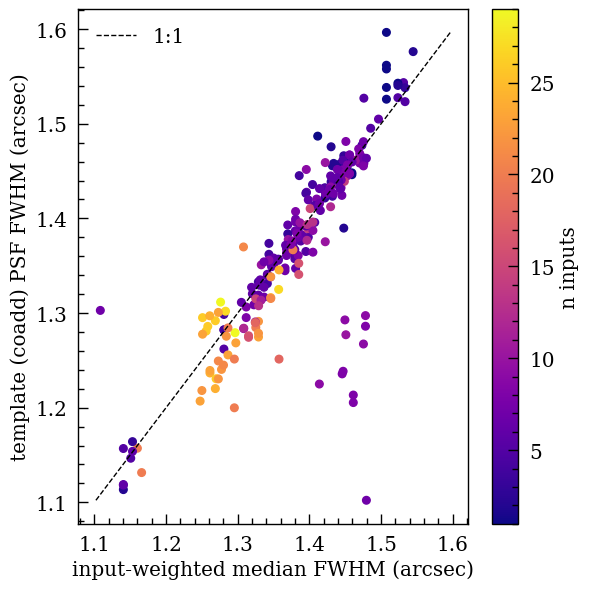

In [33]:
fig, ax = plt.subplots(figsize=(6, 6))
valid = df.dropna(subset=["template_psf_fwhm_median", "input_psf_fwhm_weighted_median"])
sc = ax.scatter(valid["input_psf_fwhm_weighted_median"], valid["template_psf_fwhm_median"],
                 c=valid["n_inputs"], cmap="plasma", s=30)
lims = [valid[["input_psf_fwhm_weighted_median", "template_psf_fwhm_median"]].min().min(),
        valid[["input_psf_fwhm_weighted_median", "template_psf_fwhm_median"]].max().max()]
ax.plot(lims, lims, "k--", lw=1, label="1:1")
ax.set_xlabel("input-weighted median FWHM (arcsec)")
ax.set_ylabel("template (coadd) PSF FWHM (arcsec)")
ax.legend()
fig.colorbar(sc, ax=ax, label="n inputs")
fig.tight_layout()
# fig.savefig(os.path.join(OUTPUT_DIR,"PSF_across_Templates_corr.pdf"),dpi=300)

## Patches worth a second look

Flags, not verdicts -- each is a cheap, tunable heuristic (see the `Parameters` cell):

* **low_coverage** -- too little of the patch footprint has real data to trust the PSF estimate.
* **single_input** -- fewer than `MIN_INPUTS_FOR_CHECK` contributing images; the template/input
  sanity check above has no redundancy to lean on.
* **fwhm_outlier** -- the patch's FWHM is `OUTLIER_MAD_SIGMA` MADs from its tract/band median.
* **template_input_mismatch** -- the template and input-weighted FWHM disagree by more than
  `TEMPLATE_VS_INPUT_MAX_DIFF` arcsec.


In [12]:
def _mad(series):
    med = series.median()
    return 1.4826 * (series - med).abs().median()


tract_band_median = df.groupby(["tract", "band"])["template_psf_fwhm_median"].transform("median")
tract_band_mad = df.groupby(["tract", "band"])["template_psf_fwhm_median"].transform(_mad)

df["low_coverage"] = df["coverage_frac"] < MIN_COVERAGE_FRAC
df["single_input"] = df["n_inputs"] < MIN_INPUTS_FOR_CHECK
with np.errstate(invalid="ignore", divide="ignore"):
    df["fwhm_outlier"] = (
        (df["template_psf_fwhm_median"] - tract_band_median).abs()
        > OUTLIER_MAD_SIGMA * tract_band_mad.replace(0, np.nan)
    ).fillna(False)
df["template_input_mismatch"] = df["template_vs_input_diff"].abs() > TEMPLATE_VS_INPUT_MAX_DIFF

flag_cols = ["low_coverage", "single_input", "fwhm_outlier", "template_input_mismatch"]
df["n_flags"] = df[flag_cols].sum(axis=1)

flagged = df[df["n_flags"] > 0].sort_values("n_flags", ascending=False)
print(f"{len(flagged)} / {len(df)} patches flagged")
flagged[["tract", "patch", "band", "template_psf_fwhm_median", "coverage_frac",
         "n_inputs", "template_vs_input_diff"] + flag_cols]


366 / 1736 patches flagged


,tract,patch,band,template_psf_fwhm_median,coverage_frac,n_inputs,template_vs_input_diff,low_coverage,single_input,fwhm_outlier,template_input_mismatch
250,198,23,r,1.459441,0.042011,1,0.027984,True,True,True,False
1286,311,16,i,1.119494,0.044305,1,0.043472,True,True,True,False
1475,374,6,g,1.131814,0.001901,1,0.013801,True,True,True,False
717,251,23,z,1.451835,0.000218,1,0.033659,True,True,True,False
1192,310,30,g,1.213056,0.002269,1,-0.002709,True,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...
1543,374,11,r,1.052659,0.958858,11,-0.109997,False,False,True,False
26,195,34,i,1.215819,0.155857,1,0.014211,False,True,False,False
1555,374,23,r,1.005441,0.552168,5,0.012864,False,False,True,False
1561,374,0,z,1.484829,0.291626,2,0.012722,False,False,True,False


## Save results

In [ ]:
df.to_csv(f"{OUTPUT_DIR}/template_psf_per_patch.csv", index=False)
tract_summary.to_csv(f"{OUTPUT_DIR}/template_psf_per_tract.csv", index=False)
print(f"Wrote {OUTPUT_DIR}/template_psf_per_patch.csv ({len(df)} rows)")
print(f"Wrote {OUTPUT_DIR}/template_psf_per_tract.csv ({len(tract_summary)} rows)")
